In [14]:
from ucimlrepo import fetch_ucirepo 
  
# fetch dataset 
statlog_german_credit_data = fetch_ucirepo(id=144) 
  
# data (as pandas dataframes) 
X = statlog_german_credit_data.data.features 
y = statlog_german_credit_data.data.targets 
  
# metadata 
print(statlog_german_credit_data.metadata) 
  
# variable information 
print(statlog_german_credit_data.variables) 


{'uci_id': 144, 'name': 'Statlog (German Credit Data)', 'repository_url': 'https://archive.ics.uci.edu/dataset/144/statlog+german+credit+data', 'data_url': 'https://archive.ics.uci.edu/static/public/144/data.csv', 'abstract': 'This dataset classifies people described by a set of attributes as good or bad credit risks. Comes in two formats (one all numeric). Also comes with a cost matrix', 'area': 'Social Science', 'tasks': ['Classification'], 'characteristics': ['Multivariate'], 'num_instances': 1000, 'num_features': 20, 'feature_types': ['Categorical', 'Integer'], 'demographics': ['Other', 'Marital Status', 'Age', 'Occupation'], 'target_col': ['class'], 'index_col': None, 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 1994, 'last_updated': 'Thu Aug 10 2023', 'dataset_doi': '10.24432/C5NC77', 'creators': ['Hans Hofmann'], 'intro_paper': None, 'additional_info': {'summary': 'Two datasets are provided.  the original dataset, in the form provided by

In [15]:
# -------------------------------------------------------------------
# 1. IMPORTS
# -------------------------------------------------------------------
print("Abschnitt 1: Pakete werden importiert...")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from ucimlrepo import fetch_ucirepo 

# Preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Ziel 1.1: Klassifikation
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Ziel 1.2: Clustering
from sklearn.cluster import KMeans

# Ziel 2.1: XAI (Explainable AI)
import shap

print("Alle Pakete erfolgreich importiert.\n")

Abschnitt 1: Pakete werden importiert...
Alle Pakete erfolgreich importiert.



In [16]:
# -------------------------------------------------------------------
# 2. DATEN LADEN
# -------------------------------------------------------------------
print("Abschnitt 2: Daten werden von UCI geladen...")

# Dataset fetchen (ID 144 = Statlog German Credit Data)
statlog_german_credit_data = fetch_ucirepo(id=144) 

# Daten in Pandas DataFrames laden
X = statlog_german_credit_data.data.features 
y = statlog_german_credit_data.data.targets 

print(f"Daten geladen: {X.shape[0]} Zeilen und {X.shape[1]} Features.")
print("Erste 5 Zeilen der Features (X):")
print(X.head())
print("\nVerteilung der Zielvariable (y) vor der Bereinigung:")
print(y.value_counts())
print("\n")

Abschnitt 2: Daten werden von UCI geladen...
Daten geladen: 1000 Zeilen und 20 Features.
Erste 5 Zeilen der Features (X):
  Attribute1  Attribute2 Attribute3 Attribute4  Attribute5 Attribute6  \
0        A11           6        A34        A43        1169        A65   
1        A12          48        A32        A43        5951        A61   
2        A14          12        A34        A46        2096        A61   
3        A11          42        A32        A42        7882        A61   
4        A11          24        A33        A40        4870        A61   

  Attribute7  Attribute8 Attribute9 Attribute10  Attribute11 Attribute12  \
0        A75           4        A93        A101            4        A121   
1        A73           2        A92        A101            2        A121   
2        A74           2        A93        A101            3        A121   
3        A74           2        A93        A103            4        A122   
4        A73           3        A93        A101            

In [17]:
# -------------------------------------------------------------------
# 3. DATEN-PREPROCESSING
# Vorbereitung der Daten für die ML-Modelle
# -------------------------------------------------------------------
print("Abschnitt 3: Daten-Preprocessing wird definiert...")

# 3.1 Zielvariable (y) bereinigen
#  1 = Good, 2 = Bad.
# Mapping = Good (positiv) und 0 = Bad (negativ) 
y_processed = y.squeeze().map({1: 1, 2: 0})

# 3.2 Features (X) für Preprocessing vorbereiten
# Identifiziere numerische und kategoriale Spalten
numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(include='object').columns.tolist()

print(f"Identifizierte numerische Features: {len(numeric_features)}")
print(f"Identifizierte kategoriale Features: {len(categorical_features)}")

# 3.3 Erstelle die Preprocessing-Pipelines
# Pipeline für numerische Daten: Fehlende Werte mit dem Mittelwert füllen und skalieren
numeric_transformer = Pipeline(steps=[
    ('scaler', StandardScaler())
])

# Pipeline für kategoriale Daten: Fehlende Werte mit einer Konstante füllen und One-Hot-Encoding anwenden
categorical_transformer = Pipeline(steps=[
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

# 3.4 Kombiniere die Pipelines mit ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ])

print("Preprocessing-Pipeline erfolgreich definiert.\n")

Abschnitt 3: Daten-Preprocessing wird definiert...
Identifizierte numerische Features: 7
Identifizierte kategoriale Features: 13
Preprocessing-Pipeline erfolgreich definiert.



In [18]:
# -------------------------------------------------------------------
# 4. MICRO-ZIEL 1.1: KREDITRISIKO-BEWERTUNG (KLASSIFIKATION)
# -------------------------------------------------------------------
print("Abschnitt 4 (Micro-Ziel 1.1): Klassifikationsmodell wird trainiert...")

# 4.1 Daten aufteilen (Train-Test-Split)
X_train, X_test, y_train, y_test = train_test_split(X, y_processed, test_size=0.3, random_state=42)

# 4.2 Vollständige ML-Pipeline erstellen
# Kette: Preprocessor -> RandomForestClassifier
model_rf = RandomForestClassifier(n_estimators=100, random_state=42)

classification_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', model_rf)
])

# 4.3 Pipeline trainieren
classification_pipeline.fit(X_train, y_train)
print("Klassifikationsmodell erfolgreich trainiert.")

# 4.4 Modell evaluieren
y_pred = classification_pipeline.predict(X_test)

print("\n--- Modell-Evaluation (Klassifikation) ---")
print("Guiding Question 1.1 / Task 4: Performance des Modells")
print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=['Bad Loan (0)', 'Good Loan (1)']))
print("\n")

Abschnitt 4 (Micro-Ziel 1.1): Klassifikationsmodell wird trainiert...
Klassifikationsmodell erfolgreich trainiert.

--- Modell-Evaluation (Klassifikation) ---
Guiding Question 1.1 / Task 4: Performance des Modells
Accuracy: 0.7700

Confusion Matrix:
[[ 35  56]
 [ 13 196]]

Classification Report:
               precision    recall  f1-score   support

 Bad Loan (0)       0.73      0.38      0.50        91
Good Loan (1)       0.78      0.94      0.85       209

     accuracy                           0.77       300
    macro avg       0.75      0.66      0.68       300
 weighted avg       0.76      0.77      0.75       300





Abschnitt 5 (Micro-Ziel 1.2): Clustering-Modell wird trainiert...
Führe Elbow-Methode zur Bestimmung von K aus...


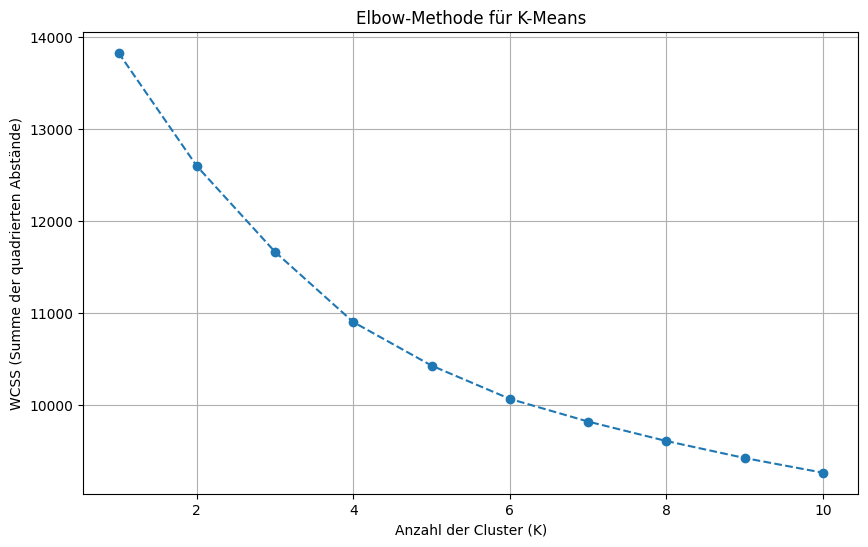

Bitte wählen Sie 'K' basierend auf dem 'Ellbogen' im Plot (z.B. K=4).
Finales K-Means-Modell mit K=4 trainiert.




In [19]:
# -------------------------------------------------------------------
# 5. MICRO-ZIEL 1.2: KUNDENSEGMENTIERUNG (CLUSTERING)
# -------------------------------------------------------------------
print("Abschnitt 5 (Micro-Ziel 1.2): Clustering-Modell wird trainiert...")

# 5.1 Daten für Clustering vorbereiten
# Unsupervised für gesamten Datensatz X
# Für K-Menas transformieren
X_processed = preprocessor.fit_transform(X)

# 5.2 Elbow-Methode 
print("Führe Elbow-Methode zur Bestimmung von K aus...")
wcss = []
k_range = range(1, 11)
for i in k_range:
    kmeans = KMeans(n_clusters=i, init='k-means++', n_init=10, random_state=42)
    kmeans.fit(X_processed)
    wcss.append(kmeans.inertia_)

# Plot der Elbow-Methode
plt.figure(figsize=(10, 6))
plt.plot(k_range, wcss, marker='o', linestyle='--')
plt.title('Elbow-Methode für K-Means')
plt.xlabel('Anzahl der Cluster (K)')
plt.ylabel('WCSS (Summe der quadrierten Abstände)')
plt.grid(True)
plt.show()
print("Bitte wählen Sie 'K' basierend auf dem 'Ellbogen' im Plot (z.B. K=4).")

# 5.3 Finales K-Means-Modell trainieren
# Wir wählen K=4 als Beispiel basierend auf typischen Ergebnissen für diesen Plot
chosen_k = 4
final_kmeans = KMeans(n_clusters=chosen_k, init='k-means++', n_init=10, random_state=42)
cluster_labels = final_kmeans.fit_predict(X_processed)

print(f"Finales K-Means-Modell mit K={chosen_k} trainiert.")
print("\n")

Abschnitt 6 (Micro-Ziel 2.1): SHAP-Erklärungen werden generiert...
SHAP-Werte berechnet.

--- DEBUG: SHAPE-ANALYSE ---
Shape der Test-Daten (X_test_processed): (300, 61)
Shape der rohen SHAP-Werte:              (300, 61, 2)
Shape des Explainer Base Value:          [0.29978571 0.70021429]
--------------------------------

--- Globale Modellerklärung (Feature Importance) ---
DEBUG: Shape der gesliceten SHAP-Werte für Plot: (300, 61)


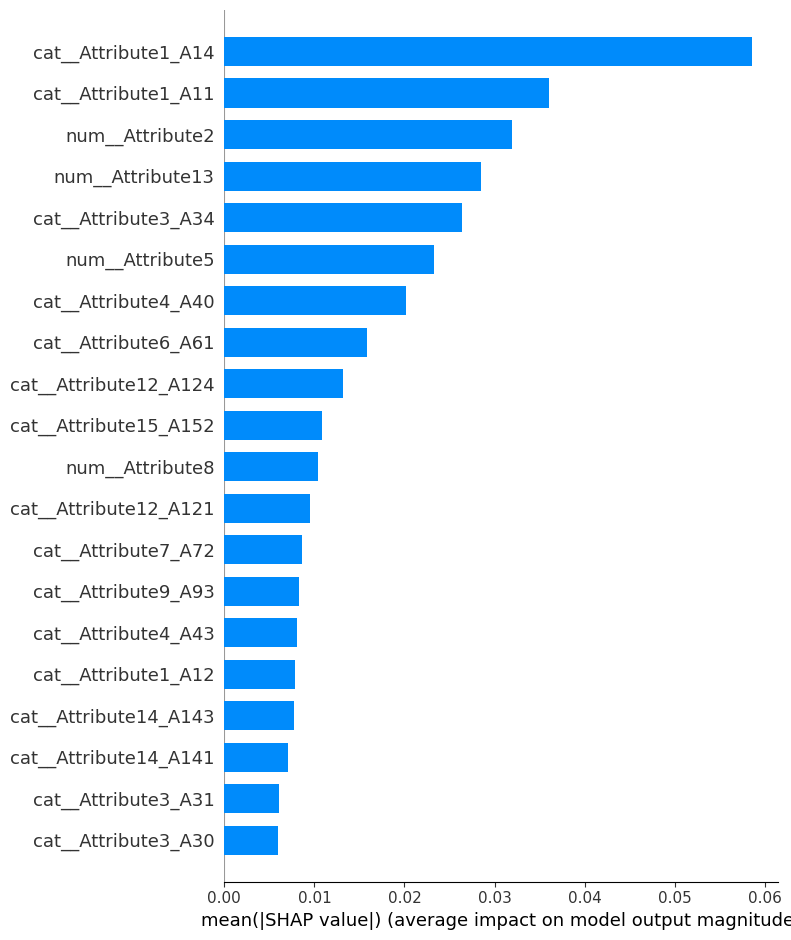


--- Lokale Modellerklärung (3 Instanzen) ---

Erklärung für Instanz 0 (echtes Label: 0):


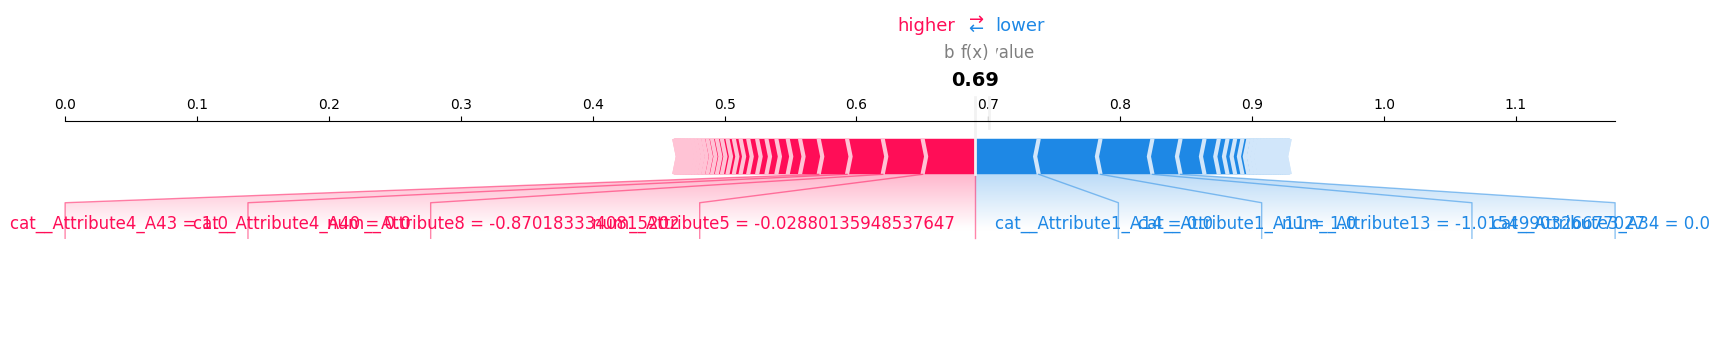


Erklärung für Instanz 1 (echtes Label: 1):


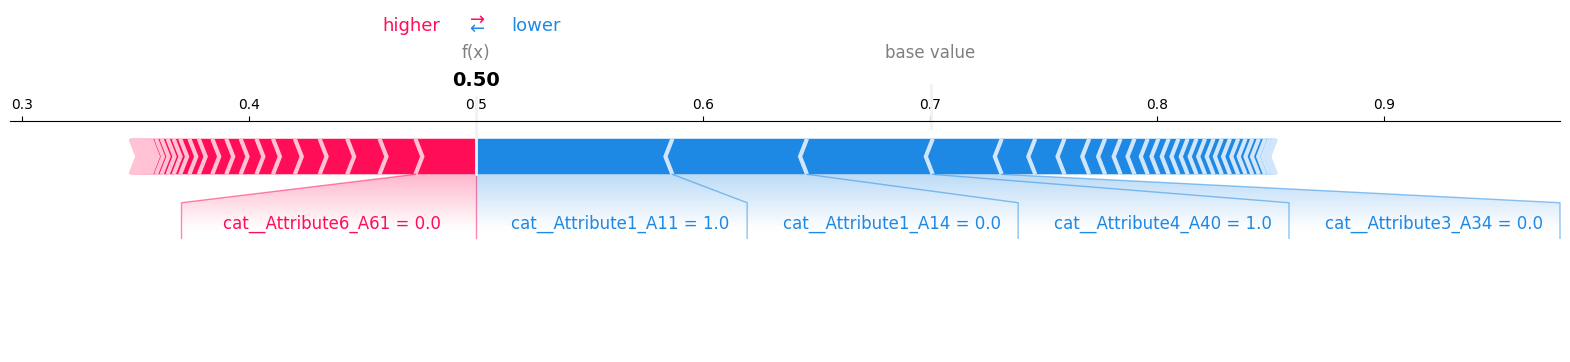


Erklärung für Instanz 2 (echtes Label: 1):


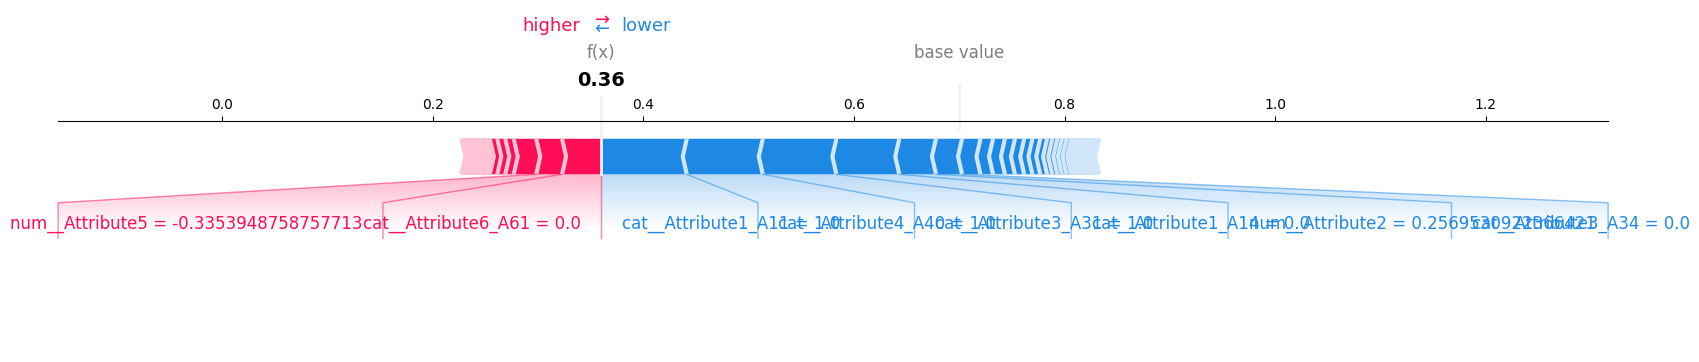



--- Cluster-Analyse (Basis für Task 2.1 / 3) ---
Durchschnittswerte der numerischen Features pro Cluster (K=4):
         Attribute2   Attribute5  Attribute8  Attribute11  Attribute13  \
cluster                                                                  
0         39.128378  8441.972973    2.587838     2.702703    34.966216   
1         18.569444  2921.486111    2.798611     2.944444    38.694444   
2         17.904943  2351.961977    3.311787     3.634981    45.889734   
3         17.368539  2208.058427    2.957303     2.393258    28.606742   

         Attribute16  Attribute18  
cluster                            
0           1.418919     1.074324  
1           1.555556     2.000000  
2           1.619772     1.000000  
3           1.229213     1.000000  

Auf Basis dieser Tabelle können Sie den Clustern Namen geben und Empfehlungen ableiten.
Spalten erfolgreich umbenannt. Neue Spalten:
['Girokonto-Status', 'Laufzeit (Monate)', 'Kredithistorie', 'Verwendungszweck', 'Kredithöhe

In [20]:
# -------------------------------------------------------------------
# 6. MICRO-ZIEL 2.1: ERGEBNISSE ERKLÄREN (XAI MIT SHAP)
# -------------------------------------------------------------------
print("Abschnitt 6 (Micro-Ziel 2.1): SHAP-Erklärungen werden generiert...")

try:
    # 6.1 Modell und Preprocessor extrahieren
    model_for_shap = classification_pipeline.named_steps['model']
    preprocessor_for_shap = classification_pipeline.named_steps['preprocessor']

    # 6.2 Test-Daten transformieren und Feature-Namen holen
    X_test_processed = preprocessor_for_shap.transform(X_test)
    feature_names = preprocessor_for_shap.get_feature_names_out()

    # 6.3 SHAP Explainer initialisieren und Werte berechnen
    explainer = shap.TreeExplainer(model_for_shap)
    shap_values = explainer.shap_values(X_test_processed)

    print("SHAP-Werte berechnet.")

    # 6.4 Debug-Informationen
    print("\n--- DEBUG: SHAPE-ANALYSE ---")
    print(f"Shape der Test-Daten (X_test_processed): {X_test_processed.shape}")
    print(f"Shape der rohen SHAP-Werte:              {shap_values.shape}")
    print(f"Shape des Explainer Base Value:          {explainer.expected_value}")
    print("--------------------------------\n")
    
    # (Erwartete Ausgabe: (300, 61) und (300, 61, 2) und (2,))

    # 6.5 Globale Erklärung 
    print("--- Globale Modellerklärung (Feature Importance) ---")
    
    # KORREKTUR: 
    # shap_values ist ein 3D-Array (300, 61, 2).
    # Wir brauchen alle Zeilen, alle Features, aber nur Klasse 1.
    # Der korrekte Slice ist [:, :, 1]
    shap_values_for_plot = shap_values[:, :, 1]
    
    print(f"DEBUG: Shape der gesliceten SHAP-Werte für Plot: {shap_values_for_plot.shape}")

    shap.initjs()
    shap.summary_plot(shap_values_for_plot,  # <--- HIER IST DIE KORREKTUR
                      X_test_processed,
                      feature_names=feature_names,
                      plot_type="bar", 
                      title="Globale Feature Importance (für Klasse 'Good Loan')")
    
    # 6.6 Lokale Erklärung (Guiding Question 2.1 / Task 1)
    print("\n--- Lokale Modellerklärung (3 Instanzen) ---")
    
    # DataFrame für die lesbare Anzeige
    X_test_processed_df = pd.DataFrame(X_test_processed, columns=feature_names)
    
    # KORREKTUR: Auch hier den 3D-Array korrekt slicen.
    # Wir brauchen Instanz [i], alle Features [:], und Klasse 1 [, 1]
    # explainer.expected_value ist (2,), wir brauchen den Wert für Klasse 1.

    # Instanz 0
    instance_index = 0
    shap_values_instance_0 = shap_values[instance_index, :, 1] 
    print(f"\nErklärung für Instanz {instance_index} (echtes Label: {y_test.iloc[instance_index]}):")
    shap.force_plot(explainer.expected_value[1], 
                    shap_values_instance_0, 
                    X_test_processed_df.iloc[instance_index,:],
                    matplotlib=True)

    # Instanz 1
    instance_index = 1
    shap_values_instance_1 = shap_values[instance_index, :, 1] 
    print(f"\nErklärung für Instanz {instance_index} (echtes Label: {y_test.iloc[instance_index]}):")
    shap.force_plot(explainer.expected_value[1], 
                    shap_values_instance_1, 
                    X_test_processed_df.iloc[instance_index,:],
                    matplotlib=True)

    # Instanz 2
    instance_index = 2
    shap_values_instance_2 = shap_values[instance_index, :, 1] 
    print(f"\nErklärung für Instanz {instance_index} (echtes Label: {y_test.iloc[instance_index]}):")
    shap.force_plot(explainer.expected_value[1], 
                    shap_values_instance_2, 
                    X_test_processed_df.iloc[instance_index,:],
                    matplotlib=True)

    # 6.7 Cluster Erklärung 
    X_with_clusters = X.copy()
    X_with_clusters['cluster'] = cluster_labels
    X_with_clusters['credit_risk'] = y_processed 

    print("\n\n--- Cluster-Analyse (Basis für Task 2.1 / 3) ---")
    print(f"Durchschnittswerte der numerischen Features pro Cluster (K={chosen_k}):")
    print(X_with_clusters.groupby('cluster')[numeric_features].mean())
    print("\nAuf Basis dieser Tabelle können Sie den Clustern Namen geben und Empfehlungen ableiten.")

except NameError as e:
    print(f"\nFEHLER: Eine Variable wurde nicht gefunden: {e}")
    print("BITTE STELLEN SIE SICHER, DASS SIE DEN KERNEL NEU GESTARTET HABEN")
    print("UND ALLE ZELLEN (1-5) VOR DIESER ZELLE AUSGEFÜHRT HABEN.")
except Exception as e:
    print(f"\nEin unerwarteter Fehler ist aufgetreten: {e}")

    print("Abschnitt 7.5: Spalten für das Dashboard umbenennen...")

# 1. Definiere das Mapping (Alter Name -> Neuer Name)
# (Basiert auf der Attribut-Erklärung)
rename_dict = {
    # Original-Features
    'Attribute1': 'Girokonto-Status',
    'Attribute2': 'Laufzeit (Monate)',
    'Attribute3': 'Kredithistorie',
    'Attribute4': 'Verwendungszweck',
    'Attribute5': 'Kredithöhe',
    'Attribute6': 'Sparkonto',
    'Attribute7': 'Beschäftigungsdauer',
    'Attribute8': 'Ratenhöhe (% Einkommen)',
    'Attribute9': 'Status & Geschlecht',
    'Attribute10': 'Bürgen',
    'Attribute11': 'Wohnsitzdauer',
    'Attribute12': 'Eigentum',
    'Attribute13': 'Alter',
    'Attribute14': 'Andere Ratenpläne',
    'Attribute15': 'Wohnsituation',
    'Attribute16': 'Anzahl Kredite',
    'Attribute17': 'Beruf',
    'Attribute18': 'Unterhaltspflichtige',
    'Attribute19': 'Telefon',
    'Attribute20': 'Gastarbeiter',
    
    # Neue Features (aus unserem Skript)
    'cluster': 'Kundensegment',
    'credit_risk': 'Kreditrisiko (0=Schlecht, 1=Gut)'
}

# 2. Wende die Umbenennung auf das DataFrame an
# Wir verwenden 'X_with_clusters' (aus Abschnitt 6.7)
try:
    df_renamed = X_with_clusters.rename(columns=rename_dict)
    
    print("Spalten erfolgreich umbenannt. Neue Spalten:")
    print(df_renamed.columns.tolist())

except KeyError as e:
    print(f"Fehler beim Umbenennen: Spalte {e} nicht gefunden.")
    print("Stelle sicher, dass 'X_with_clusters' die Original-Spaltennamen hat.")
    df_renamed = X_with_clusters # Im Fehlerfall weiter mit alten Namen

In [21]:
# -------------------------------------------------------------------
# 7. MICRO-ZIEL 2.2: EXPORT FÜR POWERBI DASHBOARD - AKTUALISIERT
# -------------------------------------------------------------------
print("Abschnitt 7 (Aktualisiert): Daten für PowerBI werden exportiert...")

# 1. Definiere den neuen Dateinamen
output_filename_renamed = "german_credit_data_renamed.csv"

# 2. Speichere den umbenannten DataFrame
df_renamed.to_csv(output_filename_renamed, index=False)

print(f"Finale Daten erfolgreich in '{output_filename_renamed}' gespeichert.")
print("Diese Datei enthält jetzt die sauberen Spaltennamen für PowerBI.")

Abschnitt 7 (Aktualisiert): Daten für PowerBI werden exportiert...
Finale Daten erfolgreich in 'german_credit_data_renamed.csv' gespeichert.
Diese Datei enthält jetzt die sauberen Spaltennamen für PowerBI.


Abschnitt 8: Cluster werden mit PCA visualisiert...


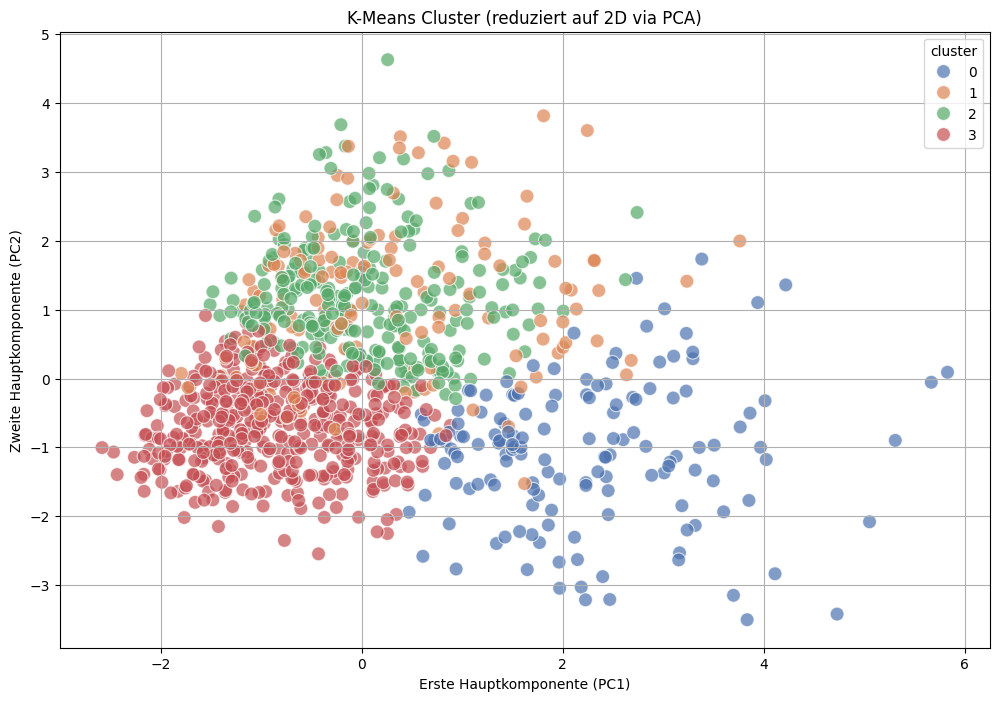

In [22]:
# -------------------------------------------------------------------
# 8. CLUSTER-VISUALISIERUNG (mit PCA)
# -------------------------------------------------------------------
from sklearn.decomposition import PCA
import seaborn as sns
import matplotlib.pyplot as plt

print("Abschnitt 8: Cluster werden mit PCA visualisiert...")

# 1. PCA-Modell initialisieren, um 61 Dimensionen auf 2 zu reduzieren
# Wir verwenden X_processed (aus Abschnitt 5), da K-Means darauf trainiert wurde
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_processed)

# 2. Ein neues DataFrame für das Plotting erstellen
pca_df = pd.DataFrame(data=X_pca, columns=['PC1', 'PC2'])
pca_df['cluster'] = cluster_labels # cluster_labels (aus Abschnitt 5)
pca_df['cluster'] = pca_df['cluster'].astype('category') # Wichtig für Seaborn

# 3. Den Scatterplot erstellen
plt.figure(figsize=(12, 8))
sns.scatterplot(
    x="PC1", y="PC2",
    hue="cluster",
    palette=sns.color_palette("deep", n_colors=chosen_k), # chosen_k (aus Abschnitt 5)
    data=pca_df,
    legend="full",
    alpha=0.7,
    s=100
)

plt.title('K-Means Cluster (reduziert auf 2D via PCA)')
plt.xlabel('Erste Hauptkomponente (PC1)')
plt.ylabel('Zweite Hauptkomponente (PC2)')
plt.grid(True)
plt.show()

Abschnitt 9 (Aktualisiert): Cluster werden mit Pairplot analysiert...


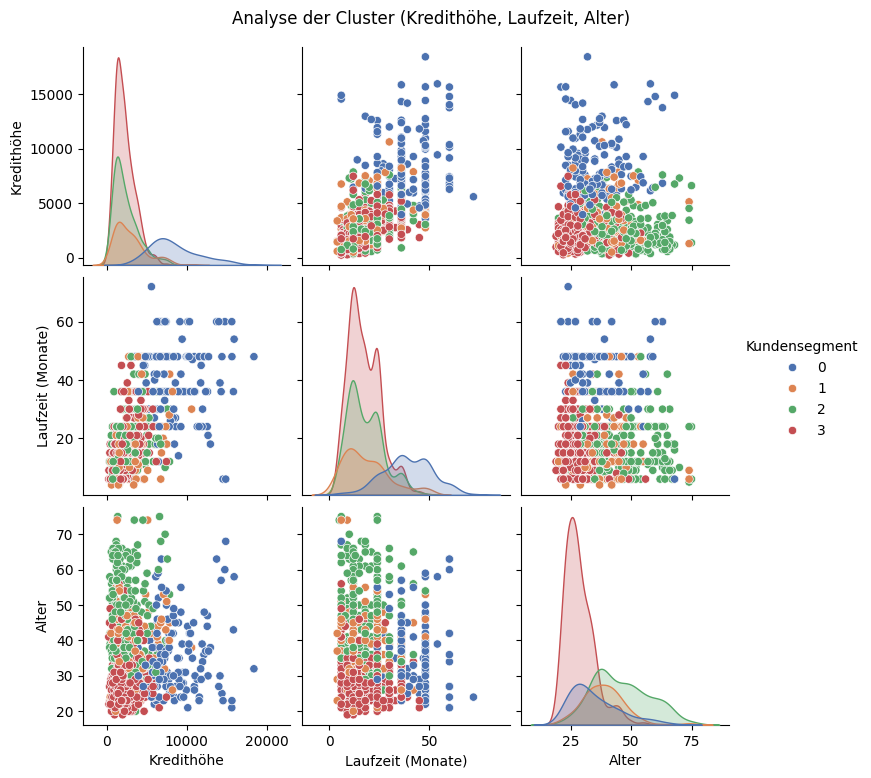

In [23]:
# -------------------------------------------------------------------
# 9. CLUSTER-VISUALISIERUNG (Pairplot) - AKTUALISIERT
# -------------------------------------------------------------------
print("Abschnitt 9 (Aktualisiert): Cluster werden mit Pairplot analysiert...")

# 1. Wähle die neuen, lesbaren Spaltennamen
features_to_plot_renamed = ['Kredithöhe', 'Laufzeit (Monate)', 'Alter']

# 2. Erstelle den Pairplot mit dem umbenannten DataFrame 'df_renamed'
sns.pairplot(df_renamed, 
             vars=features_to_plot_renamed, 
             hue='Kundensegment', 
             palette=sns.color_palette("deep", n_colors=chosen_k)
            )

plt.suptitle('Analyse der Cluster (Kredithöhe, Laufzeit, Alter)', y=1.03)
plt.show()